# First-day experiences and retention

**Question:** are newcomers whose first-day edits are rejected less likely to stay?

**Data:** the `newcomers` and `edits` tables built by `pipeline/build_tables.py`: 133,976 newcomers whose first
human edit was in 2008–2025. Definitions are in [docs/metrics_definitions.md](../../docs/metrics_definitions.md):

- **First day:** the 24 hours from a newcomer's first human edit, on every part of the wiki.
- **Reverted:** a first-day edit was identity reverted by someone else within 30 days.
- **Page deleted:** a first-day edit's page was deleted within 30 days.
- **Retained (the outcome):** at least one human edit in days 60–180 after the first edit (months 3–6).
  Both rejections happen within 31 days of the first edit, so they always come before the retention window starts.

**Earlier research:** Halfaker et al. (2013) found that on English Wikipedia (2001–2011), newcomers who were reverted
in their first edit session were less likely to survive, meaning to edit again 2–6 months later. That is close to
the main metric here. Section 5 compares the results.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DB_PATH = Path.cwd().parents[1] / "data" / "wiki.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)


def query(sql):
    # convert_dtypes keeps whole numbers as integers instead of turning them into decimals
    return con.sql(sql).df().convert_dtypes()


def rate_with_ci(retained, newcomers):
    """Retention in % and the half-width of its 95% confidence interval, in percentage points."""
    p = retained / newcomers
    return 100 * p, 100 * 1.96 * np.sqrt(p * (1 - p) / newcomers)


# Chart style: two colors for two series, recessive grid and axes, text in neutral ink
BLUE, ORANGE = "#2a78d6", "#eb6834"
TEXT, TEXT_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED, "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

One row per newcomer with what happened on their first day. The articles-only columns are used once, as a check
in section 6.

In [2]:
# Plain numeric types (no convert_dtypes): the regression library can't read pandas' newer integer types
first_day = con.sql("""
    with first_day_edits as (
        select n.user_id, e.page_namespace, e.is_reverted, e.page_deleted_within_30_days
        from newcomers n
        join edits e
          on e.editor_type = 'registered'
         and e.user_id = n.user_id
         and e.event_timestamp < n.first_edit_at + interval 1 day
        ),
    per_newcomer as (
        select
            user_id,
            count(*) as first_day_edits,
            bool_or(is_reverted) as reverted,
            bool_or(page_deleted_within_30_days) as page_deleted,
            bool_or(is_reverted and page_namespace = 0) as reverted_in_article,
            bool_or(page_deleted_within_30_days and page_namespace = 0) as page_deleted_in_article
        from first_day_edits
        group by user_id
    )
    select
        n.user_id,
        n.cohort_year,
        case when n.cohort_year <= 2012 then '2008–2012'
             when n.cohort_year <= 2016 then '2013–2016'
             when n.cohort_year <= 2020 then '2017–2020'
             else '2021–2025' end as period,
        -- peer (another user) and unknown are small groups, so they are combined, as in notebook 01
        case when n.created_by in ('self', 'system') then n.created_by else 'other' end as created_by,
        case n.first_edit_namespace
            when 0 then 'article' when 2 then 'own profile page' when 3 then 'user talk page'
            else 'other' end as first_edit_in,
        p.first_day_edits,
        case when p.first_day_edits = 1 then '1'
             when p.first_day_edits <= 4 then '2–4'
             when p.first_day_edits <= 9 then '5–9'
             else '10+' end as first_day_edits_group,
        p.reverted::int as reverted,
        p.page_deleted::int as page_deleted,
        p.reverted_in_article::int as reverted_in_article,
        p.page_deleted_in_article::int as page_deleted_in_article,
        n.retained_months_3_to_6::int as retained
    from newcomers n
    join per_newcomer p using (user_id)
""").df()

# Row counts: every newcomer has at least their first edit on the first day, so no one is lost in the join
print(f"newcomers: {len(first_day):,}, reverted: {first_day['reverted'].sum():,}, "
      f"page deleted: {first_day['page_deleted'].sum():,}")

newcomers: 133,976, reverted: 32,878, page deleted: 25,385


## 1. How common rejection is, and who stays

In [3]:
first_day["experience"] = np.select(
    [(first_day["reverted"] == 1) & (first_day["page_deleted"] == 1),
     first_day["reverted"] == 1,
     first_day["page_deleted"] == 1],
    ["Reverted and page deleted", "Reverted only", "Page deleted only"],
    default="Neither")

by_experience = (first_day.groupby("experience")
                 .agg(newcomers=("retained", "size"), retained=("retained", "sum"))
                 .reindex(["Neither", "Reverted only", "Page deleted only", "Reverted and page deleted"]))
by_experience["pct_of_newcomers"] = 100 * by_experience["newcomers"] / by_experience["newcomers"].sum()
by_experience["retained_pct"], by_experience["ci_pp"] = rate_with_ci(by_experience["retained"], by_experience["newcomers"])
by_experience.round(1)

,newcomers,retained,pct_of_newcomers,retained_pct,ci_pp
experience,,,,,
Neither,81190,6791,60.6,8.4,0.2
Reverted only,27401,762,20.5,2.8,0.2
Page deleted only,19908,625,14.9,3.1,0.2
Reverted and page deleted,5477,237,4.1,4.3,0.5


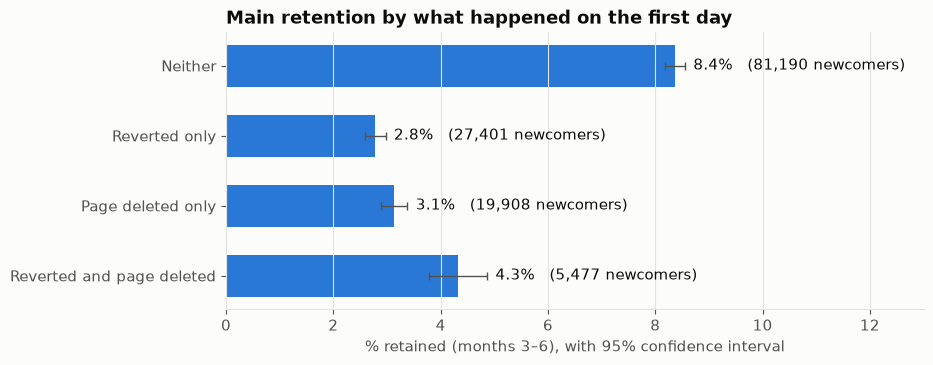

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
rows = by_experience.iloc[::-1]  # first row at the top
ax.barh(rows.index, rows["retained_pct"], xerr=rows["ci_pp"], color=BLUE, height=0.6,
        error_kw={"ecolor": TEXT_MUTED, "elinewidth": 1, "capsize": 3})
# Labels start just past each interval's right end, so they never overlap it
for y, (value, ci, n) in enumerate(zip(rows["retained_pct"], rows["ci_pp"], rows["newcomers"])):
    ax.annotate(f"{value:.1f}%   ({n:,} newcomers)", (value + ci, y), xytext=(6, 0), textcoords="offset points",
                va="center", color=TEXT)
ax.set_title("Main retention by what happened on the first day")
ax.set_xlabel("% retained (months 3–6), with 95% confidence interval")
ax.set_xlim(0, 13)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
plt.show()

## 2. The hidden factor: how much newcomers do on day one

Newcomers who make more edits on their first day have more chances to be reverted, and they are also more likely
to stay. Comparing all reverted newcomers with all the others mixes these two things. Comparing newcomers who made
the **same number** of first-day edits takes that factor out.

In [5]:
by_edits = first_day.groupby("first_day_edits_group").agg(
    newcomers=("retained", "size"),
    pct_reverted=("reverted", "mean"),
    pct_page_deleted=("page_deleted", "mean"),
    retained_pct=("retained", "mean"),
).reindex(["1", "2–4", "5–9", "10+"])
by_edits[["pct_reverted", "pct_page_deleted", "retained_pct"]] *= 100
by_edits.round(1)

,newcomers,pct_reverted,pct_page_deleted,retained_pct
first_day_edits_group,,,,
1,74548,18.2,12.7,5.2
2–4,41054,28.3,21.7,6.2
5–9,11004,38.3,33.4,8.5
10+,7370,47.1,44.9,14.5


In [6]:
def retention_by(group_column, flag_column, order):
    """Retention with 95% intervals for newcomers with and without the flag, within each group."""
    table = (first_day.groupby([group_column, flag_column])["retained"]
             .agg(newcomers="size", retained="sum").reset_index())
    table["retained_pct"], table["ci_pp"] = rate_with_ci(table["retained"], table["newcomers"])
    return table.pivot(index=group_column, columns=flag_column).reindex(order)


edits_order = ["1", "2–4", "5–9", "10+"]
reverted_by_edits = retention_by("first_day_edits_group", "reverted", edits_order)
deleted_by_edits = retention_by("first_day_edits_group", "page_deleted", edits_order)
reverted_by_edits[["newcomers", "retained_pct"]].round(1)

newcomers        retained_pct     
reverted                      0      1            0    1
first_day_edits_group                                   
1                         60967  13581          5.9  1.7
2–4                       29444  11610          7.8  2.4
5–9                        6787   4217         11.4  3.8
10+                        3900   3470         19.0  9.4

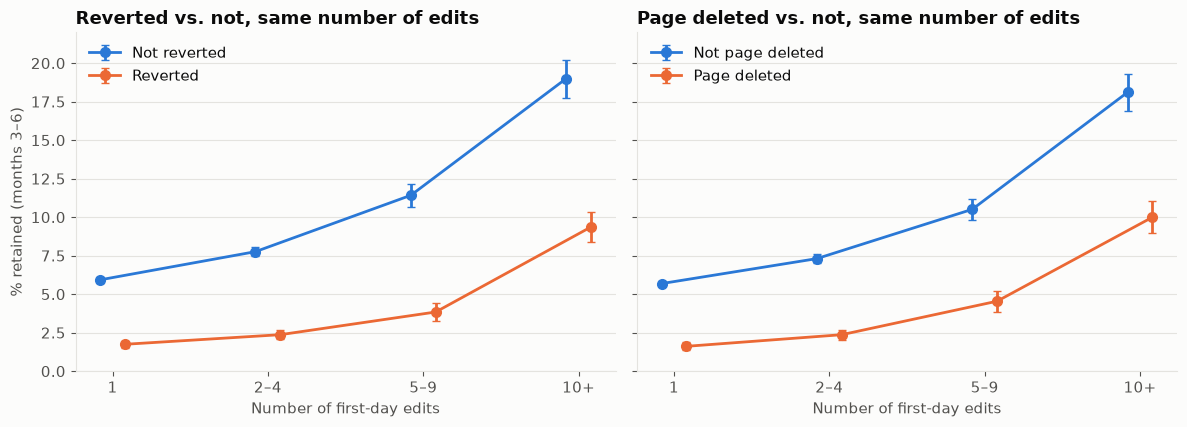

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
x = np.arange(len(edits_order))

for ax, table, label in [(axes[0], reverted_by_edits, "reverted"), (axes[1], deleted_by_edits, "page deleted")]:
    for flag, color, name, shift in [(0, BLUE, f"Not {label}", -0.08), (1, ORANGE, label.capitalize(), 0.08)]:
        ax.errorbar(x + shift, table[("retained_pct", flag)], yerr=table[("ci_pp", flag)], color=color,
                    marker="o", markersize=7, linewidth=2, capsize=3, label=name)
    ax.set_xticks(x, labels=edits_order)
    ax.set_xlabel("Number of first-day edits")
    ax.legend(frameon=False, loc="upper left")

axes[0].set_title("Reverted vs. not, same number of edits")
axes[1].set_title("Page deleted vs. not, same number of edits")
axes[0].set_ylabel("% retained (months 3–6)")
axes[0].set_ylim(0, 22)
plt.tight_layout()
plt.show()

## 3. Over the years, and by creation method

If the gap were a feature of one period or one kind of account, it would show here.

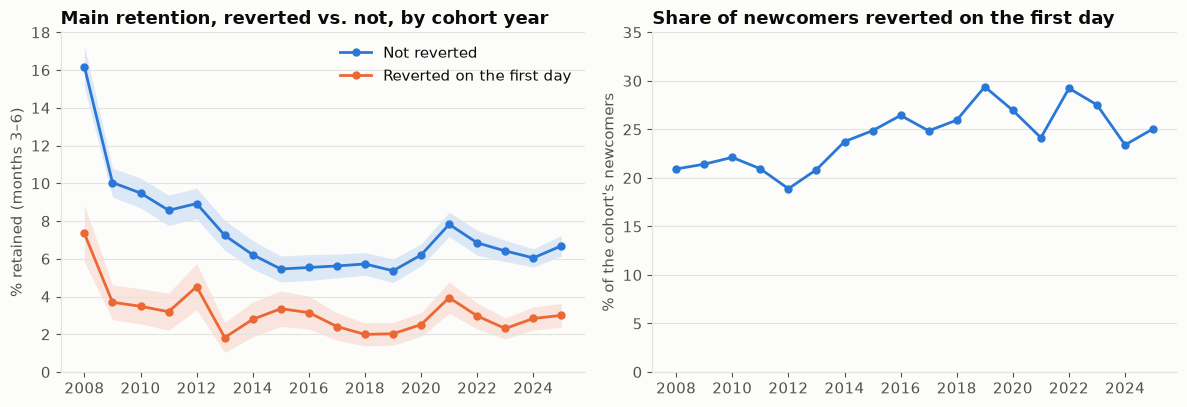

In [8]:
by_year = (first_day.groupby(["cohort_year", "reverted"])["retained"]
           .agg(newcomers="size", retained="sum").reset_index())
by_year["retained_pct"], by_year["ci_pp"] = rate_with_ci(by_year["retained"], by_year["newcomers"])
by_year = by_year.pivot(index="cohort_year", columns="reverted")

share_reverted = 100 * first_day.groupby("cohort_year")["reverted"].mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.2))
for flag, color, name in [(0, BLUE, "Not reverted"), (1, ORANGE, "Reverted on the first day")]:
    rate, ci = by_year[("retained_pct", flag)], by_year[("ci_pp", flag)]
    left.fill_between(by_year.index, rate - ci, rate + ci, color=color, alpha=0.15, linewidth=0)
    left.plot(by_year.index, rate, color=color, linewidth=2, marker="o", markersize=5, label=name)
left.set_title("Main retention, reverted vs. not, by cohort year")
left.set_ylabel("% retained (months 3–6)")
left.set_ylim(0, 18)
left.legend(frameon=False, loc="upper right")

right.plot(share_reverted.index, share_reverted, color=BLUE, linewidth=2, marker="o", markersize=5)
right.set_title("Share of newcomers reverted on the first day")
right.set_ylabel("% of the cohort's newcomers")
right.set_ylim(0, 35)

for ax in (left, right):
    ax.set_xticks(range(2008, 2026, 2))
plt.tight_layout()
plt.show()

In [9]:
period_order = ["2008–2012", "2013–2016", "2017–2020", "2021–2025"]
pd.concat({
    "by period": retention_by("period", "reverted", period_order)[["newcomers", "retained_pct"]],
    "by creation method": retention_by("created_by", "reverted", ["system", "self", "other"])[["newcomers", "retained_pct"]],
}).round(1)

newcomers        retained_pct     
reverted                             0      1            0    1
by period          2008–2012     24953   6602         10.5  4.3
                   2013–2016     16544   5239          6.1  2.8
                   2017–2020     22428   8209          5.8  2.2
                   2021–2025     37173  12828          6.7  3.0
by creation method system        66237  16374          8.9  4.3
                   self          31436  15773          4.0  1.6
                   other          3425    731          8.8  7.0

## 4. All factors at once: logistic regression

The tables compare one factor at a time. A **logistic regression** is a model that estimates the effect of every
factor together, each one **holding the others fixed**. Here the factors are being reverted, having a page deleted,
the number of first-day edits, the cohort year, the creation method, and where the first edit was made.

How to read its results:

- **Odds** are another way to state a chance: a 6% chance is odds of 6 to 94, or 0.064.
- An **odds ratio** compares a group's odds with a reference group's. 1 means no difference; 0.5 means half the odds.
  When a rate is low, as retention is here, an odds ratio is close to the ratio of the two rates: 0.5 is roughly
  "retained half as often".
- Each factor's reference group is named in the chart (for example, newcomers with 1 first-day edit, or who signed
  up here). The cohort year is in the model as 18 separate groups, so every comparison is in effect made within the
  same year. Those 17 odds ratios aren't shown: notebook 01 covers the years.
- The **95% confidence interval** works as before: if it doesn't include 1, the difference is larger than chance.

In [10]:
formula = (
    "retained ~ reverted + page_deleted"
    " + C(first_day_edits_group, Treatment('1'))"
    " + C(cohort_year)"
    " + C(created_by, Treatment('self'))"
    " + C(first_edit_in, Treatment('article'))"
)
model = smf.logit(formula, data=first_day).fit(disp=0)

labels = {
    "reverted": "Reverted on the first day (vs. not)",
    "page_deleted": "Page deleted (vs. not)",
    "C(first_day_edits_group, Treatment('1'))[T.2–4]": "2–4 first-day edits (vs. 1)",
    "C(first_day_edits_group, Treatment('1'))[T.5–9]": "5–9 first-day edits (vs. 1)",
    "C(first_day_edits_group, Treatment('1'))[T.10+]": "10+ first-day edits (vs. 1)",
    "C(created_by, Treatment('self'))[T.system]": "Created automatically (vs. signed up here)",
    "C(created_by, Treatment('self'))[T.other]": "Created by another user or unknown (vs. signed up here)",
    "C(first_edit_in, Treatment('article'))[T.own profile page]": "First edit on own profile page (vs. article)",
    "C(first_edit_in, Treatment('article'))[T.user talk page]": "First edit on a user talk page (vs. article)",
    "C(first_edit_in, Treatment('article'))[T.other]": "First edit elsewhere (vs. article)",
}
odds_ratios = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(model.conf_int()[0]),
    "ci_high": np.exp(model.conf_int()[1]),
    "p_value": model.pvalues,
}).loc[list(labels)].rename(index=labels)
print(f"newcomers in the model: {int(model.nobs):,}")
odds_ratios.round(3)

newcomers in the model: 133,976


,odds_ratio,ci_low,ci_high,p_value
Reverted on the first day (vs. not),0.369,0.344,0.396,0.0
Page deleted (vs. not),0.398,0.369,0.429,0.0
2–4 first-day edits (vs. 1),1.475,1.399,1.555,0.0
5–9 first-day edits (vs. 1),2.572,2.380,2.780,0.0
10+ first-day edits (vs. 1),5.769,5.327,6.247,0.0
Created automatically (vs. signed up here),2.597,2.446,2.758,0.0
Created by another user or unknown (vs. signed up here),2.089,1.837,2.375,0.0
First edit on own profile page (vs. article),1.238,1.161,1.321,0.0
First edit on a user talk page (vs. article),0.636,0.549,0.738,0.0
First edit elsewhere (vs. article),1.396,1.299,1.500,0.0


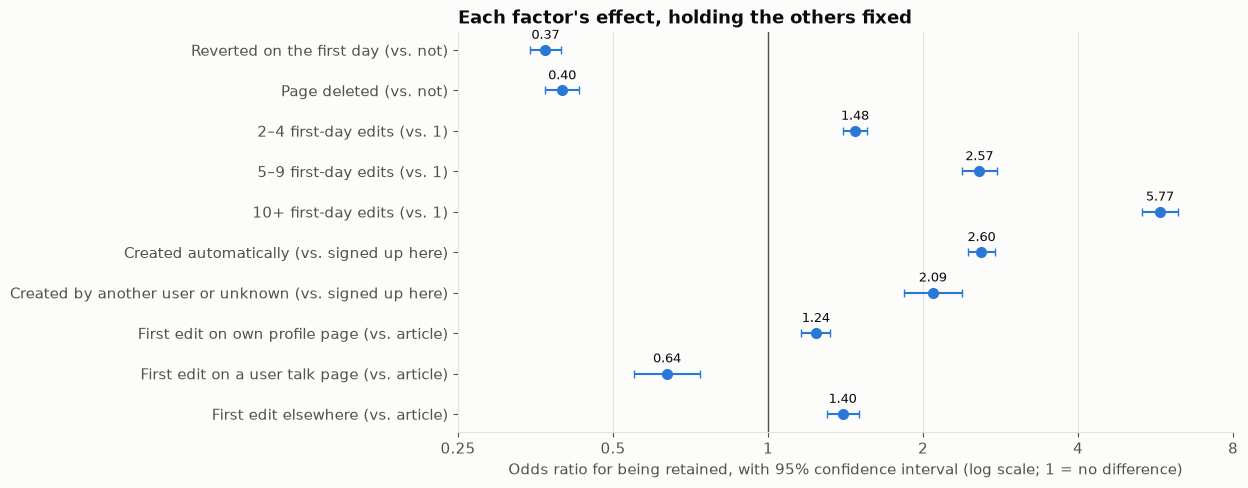

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.2))
rows = odds_ratios.iloc[::-1]
y = np.arange(len(rows))
ax.errorbar(rows["odds_ratio"], y, xerr=[rows["odds_ratio"] - rows["ci_low"], rows["ci_high"] - rows["odds_ratio"]],
            fmt="o", color=BLUE, markersize=7, capsize=3, linewidth=1.5)
ax.axvline(1, color=TEXT_MUTED, linewidth=1)
for yy, value in zip(y, rows["odds_ratio"]):
    ax.annotate(f"{value:.2f}", (value, yy), xytext=(0, 8), textcoords="offset points", ha="center", color=TEXT,
                fontsize=9)
ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8], labels=["0.25", "0.5", "1", "2", "4", "8"])
ax.xaxis.set_minor_locator(plt.NullLocator())  # no extra ticks between the labeled ones
ax.set_yticks(y, labels=rows.index)
ax.set_xlabel("Odds ratio for being retained, with 95% confidence interval (log scale; 1 = no difference)")
ax.set_title("Each factor's effect, holding the others fixed")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
plt.show()

**The same result in percentages.** The model can estimate the overall retention rate if every newcomer had been
reverted on their first day, and if none had, with every other factor left as it really was.

In [12]:
scenarios = {}
for name, value in [("No one reverted", 0), ("Everyone reverted", 1)]:
    scenario = first_day.assign(reverted=value)
    scenarios[name] = 100 * model.predict(scenario).mean()
pd.Series(scenarios, name="estimated retention %").round(1)

No one reverted      7.4
Everyone reverted    3.0
Name: estimated retention %, dtype: float64

## 5. Comparison with Halfaker et al. (2013)

The paper reports its model as coefficients. An odds ratio is e raised to the power of the coefficient, so
they convert directly. Its model differs from this one in a few ways: English Wikipedia newcomers from
2001–2011, the first edit session instead of the first day, articles only, a deletion at any later time, and two
more factors, "received a message" and "reverted by a tool". A tool revert adds its own effect on top of
"reverted".

In [13]:
paper = pd.DataFrame({
    "paper_all_newcomers": {"Reverted": -0.68, "Page deleted": -1.45},
    "paper_good_faith_newcomers": {"Reverted": -0.50, "Page deleted": -0.80},
}).apply(np.exp)
paper["this_analysis"] = [odds_ratios.loc[labels["reverted"], "odds_ratio"],
                          odds_ratios.loc[labels["page_deleted"], "odds_ratio"]]
paper.round(2)

,paper_all_newcomers,paper_good_faith_newcomers,this_analysis
Reverted,0.51,0.61,0.37
Page deleted,0.23,0.45,0.40


## 6. Checks

1. **Articles only**, as in the paper: rejections count only when they happened in an article.
2. **Has the effect of a revert changed over time?** The same model, with a separate revert odds ratio for each period.

In [14]:
articles_only = smf.logit(formula.replace("reverted + page_deleted", "reverted_in_article + page_deleted_in_article"),
                          data=first_day).fit(disp=0)
by_period = smf.logit(formula.replace("reverted +", "reverted:C(period) +"),
                      data=first_day).fit(disp=0)

checks = pd.DataFrame({
    "odds_ratio": np.exp(pd.concat([articles_only.params, by_period.params])),
    "ci_low": np.exp(pd.concat([articles_only.conf_int()[0], by_period.conf_int()[0]])),
    "ci_high": np.exp(pd.concat([articles_only.conf_int()[1], by_period.conf_int()[1]])),
})
checks = checks[~checks.index.duplicated()]
checks = checks.loc[["reverted_in_article", "page_deleted_in_article"]
                    + [f"reverted:C(period)[{period}]" for period in period_order]]
checks.index = ["Articles only: reverted", "Articles only: page deleted"] + [f"Reverted, {p}" for p in period_order]
checks.round(2)

,odds_ratio,ci_low,ci_high
Articles only: reverted,0.37,0.34,0.40
Articles only: page deleted,0.42,0.39,0.46
"Reverted, 2008–2012",0.37,0.32,0.42
"Reverted, 2013–2016",0.44,0.37,0.52
"Reverted, 2017–2020",0.35,0.29,0.41
"Reverted, 2021–2025",0.36,0.32,0.40


## Findings

**1. Four newcomers in ten have an edit rejected on their first day, and they stay far less often.** 24.5% had a
first-day edit reverted and 18.9% had a page deleted within 30 days; 39.4% had at least one of the two. Newcomers
with neither were retained at 8.4%, against 2.8% for those only reverted and 3.1% for those whose page was only
deleted. Newcomers with both did a little better (4.3%), because they were much more active: 12.0 first-day edits
on average, against 2.3 for newcomers with neither.

**2. The gap holds among newcomers who did the same amount on day one.** More first-day edits mean more chances to
be reverted (18% of one-edit newcomers, 47% of those with 10+), and also more chances of staying. Comparing
newcomers with the same number of edits, reverted newcomers are retained a third to half as often: 1.7% vs. 5.9%
with one edit, 9.4% vs. 19.0% with 10+. A deleted page shows the same pattern.

**3. It holds in every cohort year and for every way of creating an account.** In every year from 2008 to 2025,
newcomers who weren't reverted were retained 1.6 to 4.0 times as often as those who were. The gap is there for
automatic accounts (8.9% vs. 4.3%) and for those who signed up here (4.0% vs. 1.6%).

**4. With all factors held fixed, a first-day revert goes with odds of staying about 0.37 times as high.** That is
for newcomers with the same number of first-day edits, cohort year, creation method and place of first edit
(95% interval 0.34–0.40). A deleted page: 0.40 (0.37–0.43). In percentages, the model estimates 7.4% retention if
no newcomer had been reverted and 3.0% if every newcomer had been. Starting with 10+ edits has the largest positive
effect (5.8 times the odds of a one-edit start), followed by an automatic account (2.6).

**5. The result is in line with Halfaker et al. (2013), and points to the same open question.** The paper found odds
ratios of 0.51 for a revert and 0.23 for a deletion among all English Wikipedia newcomers. Among newcomers
hand-labeled as good-faith, the revert effect was weaker (0.61). Part of the gap comes from vandals, who are reverted
and never meant to stay. This analysis can't separate good-faith newcomers, so 0.37 mixes the two effects;
labeling first-day edits as good-faith or not would separate them.

**6. Reverts don't explain why retention fell.** The revert effect is about the same in every period (odds ratios
0.35–0.44, with overlapping intervals), and the same with articles only (0.37). The share of newcomers reverted rose
from 19–22% in 2008–2013 to 23–29% in 2014–2025. But retention fell just as steeply among newcomers who weren't
reverted (16.2% in 2008, 5.4% in 2019). With 2008's share reverted, 2019 retention would have been about 4.7%
instead of 4.4%, only 0.3 of the 9.9-point fall.

**What this does and doesn't show:** newcomers who are rejected on their first day stay much less often, whatever
their activity, year or account type. It doesn't prove that the rejection makes them leave. Good-faith
labels would narrow that question, and an A/B test is the way to answer it.